# 39 — A drift detector for saturated windows: the plug-in β disagreement (System I, N3; read-only)

Notebook 38 showed that the guarded z_T gate leaves the saturated Sc7 windows (19 of 50) to the production posterior, where they stay wrong (coverage 0.00). In a saturated window the controlled temperature leaves the setpoint, so the temperature residual cannot separate a sensor offset from loss of control. The question here: can the **disagreement of the two plug-in estimators of β**
(nb34's misspecification alarm), **d = ln β̂_jac − ln β̂_rx** (jacket balance against reactor balance; columns 30 and 31 of the S1m features), serve as a drift detector in saturated windows? The reactor-balance estimator uses the measured T, the jacket-balance estimator uses T − Tc and Qc, so a T-sensor offset should pull them apart.

**Rules (fixed before running; runbook §2f row s1).** *Threshold, on a separate set* (new seed base 5 100 000): 300 windows of Sc5 (α = 1, β = 0.5; true inlet from the notebook-35 distribution, measured Ti, Tci with ε = 0.1 K; P2, N3 sensors); the first **50 saturated** windows (more than 50% of the samples at Qc ≥ 395 L/min) are the negatives; the same 50 windows with +2 K added to the T channel are the positives (the Sc7 construction).
Flag a window iff |d| > τ, with τ the 48th smallest |d| of the 50 negatives (so at most 2 of 50 negatives, 4%, are flagged). *Evaluation on D1:* detection = the share of D1's saturated Sc7 windows flagged; false alarms = the share of D1's saturated Sc5 windows flagged (the saturated windows of Sc1–Sc4 are reported too, not gated).
**Decision:** detection ≥ 0.9 **and** false alarms ≤ 0.05 → evaluate the **extended gate** (unsaturated: |z_T| > 10 as in notebook 38; saturated: |d| > τ; flagged → drift-aware posterior, unflagged → production posterior) on D1 as in notebook 38; otherwise the saturation caveat is recorded as the result and the extended gate is not evaluated.
**Checks:** 50 saturated tuning windows found; finite; d equals ln β̂_jac − ln β̂_rx recomputed from the stored features.


In [1]:
import json, os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
warnings.filterwarnings("ignore")
import importlib, ws_eval, ws_metrics, ws_phase3, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb09_drift_aware
for _m in (ws_eval, ws_metrics, ws_phase3, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb09_drift_aware):
    importlib.reload(_m)
we, wm, P3, wi, M, P36, D = ws_eval, ws_metrics, ws_phase3, ws_inlet, nb35_measured_inlet, nb36_production_measured_inlet, nb09_drift_aware
R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()
SEED = 5_100_000; N_GEN = 300; N_NEED = 50
J, RX = 30, 31


## 1. The tuning set (separate seed): saturated Sc5 windows without and with a +2 K drift

In [2]:
th = np.tile(np.array([1.0, 0.5], np.float32), (N_GEN, 1)); inl = M._inlets(N_GEN, SEED + 1)
raw = np.array(wi.simulate(th, inl, M.PROTOCOL, SEED + 2, raw=True, **M.NOISE), np.float32)
meas = M.measured(inl[:, 1:3], 0.1, SEED + 3).astype(np.float32)
sat = (raw[:, :, 3] >= 395).mean(1) > 0.5
idx = np.where(sat)[0][:N_NEED]
print(f"generated {N_GEN} Sc5 windows, {int(sat.sum())} saturated ({sat.mean():.2f}); using the first {len(idx)}")
assert len(idx) == N_NEED
raw_pos = raw[idx].copy(); raw_pos[:, :, 1] += 2.0
f_neg = P36.features_from_raw(raw[idx], meas[idx]); f_pos = P36.features_from_raw(raw_pos, meas[idx])
assert np.isfinite(f_neg).all() and np.isfinite(f_pos).all()
d_neg, d_pos = f_neg[:, J] - f_neg[:, RX], f_pos[:, J] - f_pos[:, RX]
chk = P36.features_from_raw(raw[idx], meas[idx])[:, J] - P36.features_from_raw(raw[idx], meas[idx])[:, RX]
assert np.allclose(chk, d_neg)
tau = float(np.sort(np.abs(d_neg))[47])
print(f"tuning negatives: d median {np.median(d_neg):+.3f}, |d| 95th pct {np.percentile(np.abs(d_neg), 95):.3f}, max {np.abs(d_neg).max():.3f}")
print(f"tuning positives: d median {np.median(d_pos):+.3f}, 5-95% [{np.percentile(d_pos, 5):+.3f}, {np.percentile(d_pos, 95):+.3f}]")
print(f"tau = {tau:.4f} | tuning-set false alarms {np.mean(np.abs(d_neg) > tau):.3f}, detection {np.mean(np.abs(d_pos) > tau):.3f}")
from scipy.stats import mannwhitneyu
print(f"AUC of |d| (positives vs negatives, tuning set): {mannwhitneyu(np.abs(d_pos), np.abs(d_neg)).statistic / (N_NEED * N_NEED):.3f}")
pd.DataFrame(dict(d_neg=d_neg, d_pos=d_pos)).to_csv(R / "39_N3_tuning_d.csv", index=False)


generated 300 Sc5 windows, 238 saturated (0.79); using the first 50
tuning negatives: d median -0.012, |d| 95th pct 0.907, max 5.991
tuning positives: d median +1.436, 5-95% [+0.545, +3.754]
tau = 1.0547 | tuning-set false alarms 0.040, detection 0.780
AUC of |d| (positives vs negatives, tuning set): 0.956


## 2. Evaluation on D1: saturated Sc7 (detection) and saturated Sc5 (false alarms)

,scenario,n_saturated,flag_rate_d,d_median,role
0,Sc1,15,0.000,0.002,false alarm (reported)
1,Sc2,21,0.000,0.020,false alarm (reported)
2,Sc3,4,0.000,0.064,false alarm (reported)
3,Sc4,16,0.000,0.061,false alarm (reported)
4,Sc5,37,0.054,-0.129,FALSE ALARM (gated)
5,Sc7,19,0.105,0.676,DETECTION (drift present)


D1 saturated windows: Sc7 detection 0.105 (n = 19); Sc5 false alarms 0.054 (n = 37); Sc1-Sc4 saturated false alarms 0.000
PRE-SET BAR (detection >= 0.9 and false alarms <= 0.05): NOT MET


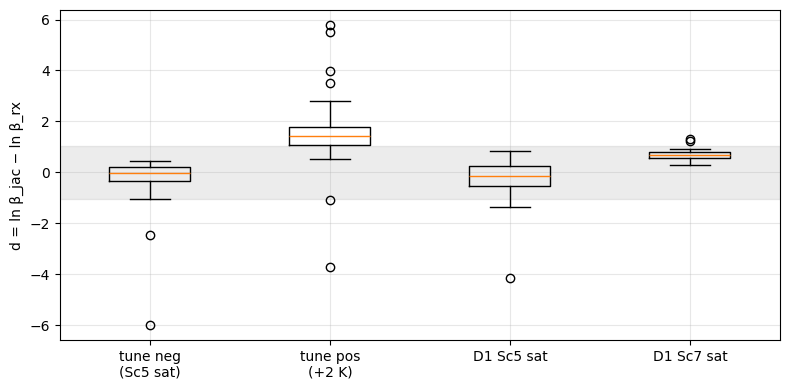

In [3]:
d1 = P3.load_d1(); X = P3.production_features(d1); sid = d1["scenario_id"]
d = X[:, J] - X[:, RX]; sat1 = (d1["x"][:, :, 3] >= 395).mean(1) > 0.5
z = (d1["x"][:, :, 1].mean(1) - 312.5) / (0.2 / np.sqrt(120.0)); flag_d = np.abs(d) > tau
rows = []
for sc, nm in ((1, "Sc1"), (2, "Sc2"), (3, "Sc3"), (4, "Sc4"), (5, "Sc5"), (7, "Sc7")):
    m = (sid == sc) & sat1
    rows.append(dict(scenario=nm, n_saturated=int(m.sum()), flag_rate_d=float(flag_d[m].mean()) if m.any() else np.nan, d_median=float(np.median(d[m])) if m.any() else np.nan,
                     role="DETECTION (drift present)" if sc == 7 else ("FALSE ALARM (gated)" if sc == 5 else "false alarm (reported)")))
ev = pd.DataFrame(rows); display(ev.round(3)); ev.to_csv(R / "39_N3_D1_saturated_rates.csv", index=False)
det = float(flag_d[(sid == 7) & sat1].mean()); fa = float(flag_d[(sid == 5) & sat1].mean()); fa_other = float(flag_d[np.isin(sid, [1, 2, 3, 4]) & sat1].mean())
PASS = bool(det >= 0.9 and fa <= 0.05)
print(f"D1 saturated windows: Sc7 detection {det:.3f} (n = {int(((sid == 7) & sat1).sum())}); Sc5 false alarms {fa:.3f} (n = {int(((sid == 5) & sat1).sum())}); Sc1-Sc4 saturated false alarms {fa_other:.3f}")
print("PRE-SET BAR (detection >= 0.9 and false alarms <= 0.05):", "MET" if PASS else "NOT MET")
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([d_neg, d_pos, d[(sid == 5) & sat1], d[(sid == 7) & sat1]], tick_labels=["tune neg\n(Sc5 sat)", "tune pos\n(+2 K)", "D1 Sc5 sat", "D1 Sc7 sat"]); ax.axhspan(-tau, tau, color="grey", alpha=.15); ax.set_ylabel("d = ln β_jac − ln β_rx"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGS / "39_N3_saturated_d.png", dpi=150); plt.show()
json.dump(dict(tau=tau, detection_Sc7_saturated=det, false_alarm_Sc5_saturated=fa, false_alarm_Sc1_4_saturated=fa_other, bar_met=PASS), open(R / "39_N3_decision.json", "w"), indent=1)


## 3. The extended gate (evaluated only if the pre-set bar is met)

In [4]:
if not PASS:
    print("Bar not met: the extended gate is NOT evaluated. The saturation caveat of notebook 38 stands (the result of this notebook).")
else:
    post_prod, _ = P3.load_production_posterior(); post_da = D.ensemble()
    s_prod, _ = we.sample_within_prior(post_prod, X, 1000, rng_seed=21)
    s_da3, _ = D.sample_box(post_da, X, 1000, seed=22); s_da = s_da3[:, :, :2]
    thv = d1["theta"][:, 2:].astype(float)
    flag_g = np.where(sat1, flag_d, np.abs(z) > 10.0)                  # extended gate: saturated -> |d| > tau; unsaturated -> |z_T| > 10
    flag_n38 = (~sat1) & (np.abs(z) > 10.0)                             # notebook 38's guarded gate
    SCN = {1: "Sc1", 2: "Sc2", 3: "Sc3", 4: "Sc4", 5: "Sc5", 7: "Sc7"}
    def table(s, label):
        yt = wm.class_of_theta(thv); yp = wm.class_of_samples(s); q05 = np.quantile(s, .05, axis=1); q95 = np.quantile(s, .95, axis=1); mean = s.mean(1); sd = s.std(1); out = []
        for sc, nm in SCN.items():
            m = sid == sc
            out.append(dict(variant=label, scenario=nm, class_acc=float((yt[m] == yp[m]).mean()), cov90_b=float(((thv[m, 1] >= q05[m, 1]) & (thv[m, 1] <= q95[m, 1])).mean()), sd_b=float(sd[m, 1].mean()), bias_b=float((mean[m, 1] - thv[m, 1]).mean())))
        return pd.DataFrame(out), yt, yp
    combos = {"extended gate (z_T unsaturated, d saturated)": np.where(flag_g[:, None, None], s_da, s_prod), "notebook 38 gate (z_T unsaturated only)": np.where(flag_n38[:, None, None], s_da, s_prod), "production 2-D only": s_prod, "drift-aware only": s_da}
    tabs, preds = [], {}
    for lab, s in combos.items():
        t_, yt, yp = table(s, lab); tabs.append(t_); preds[lab] = yp
    allt = pd.concat(tabs, ignore_index=True); display(allt.round(3)); allt.to_csv(R / "39_N3_extended_gate_three_numbers.csv", index=False)
    m15 = np.isin(sid, [1, 2, 3, 4, 5]); mf = pd.DataFrame([dict(variant=l, macro_f1_Sc1_5=wm.macro_f1(yt[m15], p[m15]), macro_f1_all_six=wm.macro_f1(yt, p)) for l, p in preds.items()]); display(mf.round(3)); mf.to_csv(R / "39_N3_extended_gate_macro_f1.csv", index=False)
    g = pd.DataFrame([dict(scenario=nm, flag_rate_all=float(flag_g[sid == sc].mean()), flag_rate_saturated=float(flag_g[(sid == sc) & sat1].mean()) if ((sid == sc) & sat1).any() else np.nan,
                           flag_rate_unsaturated=float(flag_g[(sid == sc) & ~sat1].mean()) if ((sid == sc) & ~sat1).any() else np.nan) for sc, nm in SCN.items()])
    display(g.round(3)); g.to_csv(R / "39_N3_extended_gate_rates.csv", index=False)
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


Bar not met: the extended gate is NOT evaluated. The saturation caveat of notebook 38 stands (the result of this notebook).
notebook wall time 0.1 min


## 6. Interpretation

**Pre-set outcome: the bar is NOT met, and the saturation caveat of notebook 38 stands.** On D1's saturated windows the plug-in β disagreement flags **2 of 19 Sc7 windows (detection 0.105)** and 2 of 37 saturated Sc5 windows (false alarms 0.054, just above the 5% limit); it flags none of the 56 saturated windows of Sc1–Sc4. The bar was detection ≥ 0.9 with false alarms ≤ 0.05. The extended gate was therefore not evaluated, and nothing in production changed.

**Why: the statistic carries signal, but the threshold fixed on the separate set is too high for Sc7.** On the tuning set (saturated Sc5 windows, β = 0.5, with and without +2 K) the drift moves d from a median of −0.01 to +1.44 and |d| separates the two with an AUC of 0.96, but the negatives have a long tail (|d| up to 6.0), because the jacket-balance estimator is unreliable in a window where the valve is clipped and β is small: the threshold, the 48th smallest of 50 negatives, is τ = 1.05 and detects 78% of the tuning positives.
On D1 the Sc7 windows (β = 0.85) have d between +0.28 and +1.31 (median +0.68, all positive) — shifted, but below τ in 17 of 19. The pre-set threshold was calibrated on a noisier scenario than the one it is tested on, as the rule required (separate set, Sc5), and it misses.
*Exploratory, after the fact, not part of the rule:* the signal is there (AUC of |d| for Sc7 against all 93 saturated windows of Sc1–Sc5 is 0.90; against Sc1–Sc4 only, 0.98; against saturated Sc5 only, 0.79), but even a threshold chosen on D1 itself to give 5% false alarms over those 93 windows would detect only 0.21 of the Sc7 windows. A drift detector for saturated windows from this statistic would need a scenario-dependent threshold (the noise of d grows as β falls and the valve clips),
that is, a model of the d noise, which is a different piece of work; a one-sided test on the sign of d (positive in all 19 Sc7 windows) was not pre-registered and was not tried.

**What it means for the paper.** The caveat is a result: **in saturated windows neither the temperature residual (the controller cannot hold T_sp) nor the disagreement of the two plug-in β estimators (noise comparable to the drift effect at β = 0.5–0.85) detects a +2 K temperature-sensor offset reliably.** The deployment combination of notebook 38 therefore leaves the saturated drifted windows to the production posterior unless the practitioner routes every saturated window to the drift-aware posterior
(at a macro-F1 and width price) or declares the result conditional on an unsaturated loop. The checklist entry stands as written: the sensor-fault guard applies to unsaturated windows only, and a saturated valve is reported as loss of control.

**Ledger.** Documents: the failure of both detectors in saturated windows (Sc7: z_T uninformative, |d| detects 2 of 19). Does not support: a drift detector for saturated windows.